# Team A FraudShield model development and demo

**CAI2820C** | Jorge Alvarez V, Mariela Del Rio, Javier Elizalde Ramirez, Juan Franceschi

This follows the Part II preparation notebook. We now use **all original cards and
transactions**, not the earlier reduced sample. This notebook compares two baselines,
Logistic Regression and Random Forest, locks the model and threshold on chronological
validation, and then evaluates that fixed approach on the later official test file.
The final test is not part of the development file's 80/20 split.

Run All works locally or in Colab. Source functions are embedded for a standalone
Colab run. In a fresh runtime upload both full original CSVs or ZIPs when prompted;
no Kaggle credentials are needed. Large-data training requires sufficient memory.
When saved run artifacts are present, the notebook displays them without retraining
or repeating the test evaluation. Keep the existing experiment for auditability.

**Important:** the official test has now been observed. Later changes must not use
these outcomes for tuning and still describe the same test as unseen.

## 1 Setup and shared source

In [1]:
from pathlib import Path
import base64, io, json, sys, zipfile, subprocess
import importlib.util

candidates = [Path.cwd(), Path.cwd() / 'FraudShield_Project',
              Path.cwd() / 'Part III' / 'FraudShield_Project']
PROJECT = next((p for p in candidates if (p / 'core.py').exists() and (p / 'shared/project_data.py').exists()), None)
if PROJECT is None:
    PROJECT = Path('/content/fraudshield_project') if Path('/content').exists() else Path.cwd() / 'fraudshield_project'
    PROJECT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(base64.b64decode('UEsDBBQAAAAIAM5LU11oa2RtDAYAAEkOAAAHAAAAY29yZS5weZVX627bNhT+76c4yBBI2hTVydpic+cBSeNsBZZkc9yuRWAItEjZbCVSJamkXtF33yFFyXLsZmuQxNIhz/32+eDg4GZFFKPARVUbyKQwimQGiKCgyZ07yJliImNQ8YoVXDDIpYILRWp6s+KsoMnBwcFgkCtZQkXMquAL4GUllYE/8XXgn9/LBZ60b6IuqzUQDaJqSRXqRAL+VrSRpj8UjCiRLIhmrcgzfJ5ow0tipIphpojQaE/J1CX/xIVndD4llZLvWWZSSgxp+V+ezia/XU9fvTz9I4aLyens9XRyE8PV68sJEmOgTPE7luaMmFoxPRhMr69nMHauhGma84KlaZTgkSzuWBglFaoSZjCd/PX61XRyjldvA2OtsmpZ2jyivSyIIaByYT9IaexHxs06rWRlnwviSIUUyyAeQO8nQN+yVeov+Bd3DSWgiqVUa/u8ZAKNt0/aIDmYDy5P36bT679v0KZnQ/xxhLN3s4mlnAzhezgenjz1H4PBgLIc7kjBneGuIEJF7qORMweTPGUYEwGku0SxYKr1CxDsjinQGBthijVQJSvAGsGQ14ZBXRWSULys5L12xWLl8RxQeMLKyqxHncOKcMz1G1LUbKKUVGEwWzF4efPGlSbhAitGggsqlimXQidB1JeXyaIukUpRK7fhoZgjItZh9JiSRoHlBEFKpqGstYEF2i74x5q1OkquNRdLjJ7GWkLRmpmwzXwER2Dfe1ZEnWme8zEbLr1wxT7WXLnYOiEjCOAHsHlN3ksuQi/Ky6Y5WtOorNBJR7P96b3hAlr7NrrRHprfNjfmCdeCtDGyWesdEW3WFQu1UVGC/+wfr/Au+xgGwU5Y97qVB58baV82GWzDiMoWBREfbD3VrMvktvm+M29Hz+cbVRsb0fuKJkamOFGwdbNwcxQDsybocZBJ7BrmxfsICIlTqELvcy64YT0+dKwovsUxVyzeO2jE2QG3YKrzyQ4AbMuy6uy1/WOpqDjZOy92zI+hNtl4pmo8siOPmHFQ8k+Meh0Lrsxqr3wcO98sDUPUGb1TI07VFvWxyn4l3MDot20vILbk0FaQuRfrDSBLhs6Em4tHzXmUUJNQstbwBH58/iw5eXrybNBLKvIlC2buGRPhMIbjk+FOQndNPEVlxGxZ2I4ALwuGbimiOFjjVuoyi3XzlXlva3MTQjTa/JNileCoNOGVFMw5gi2VuzQFh++ODsujQwqHv48OL0eHNz0Fdm9YcU2A/reoTSptFeDWgV/GMOzl0ZLbLQS/dEePRqqUtTCbCVlJzQ2uzBdgBeFrVeOqsgHMiLD5wDuCLYm9s9vhMRS85MY2+m3ol+DPwyiGcGvteZJfe8c/bd3YEOejhx3eG2ZtTRw5jV7xN/c61yBrozllYHAzNYWdSakoF7aKMf3LPX5aB3vQ4yuT7L9Hr+NTzR6mOe7srCBaw0UDV85qXiAGCB+iongbNnl37brPucElVuQxvI1hPXa11Mt+o8heGHQsphXeMu4yPABR4QNQ8TaKblvoNfe4w0KEdFELWrDQosi+Kd/BtUBYYa9AKSkrwMIwxIlK0jrDTVnIDNO4hsUak8LdgQV+sQcmHQBpMGjDnTjRVlWL7twzZswhvieI0pThOQ4D/QQdRXGMpk570ojZNJctNMucsE9cG73bPxeo8EqaC+wc6tvoSnp83YiEaS1sZLlIEBcvGMaXAQ4ONAEXpa00ykrZ1pUPc2NHYp1zxkc+ljpD7rQPkiwoiaEJr7dug+HG+0Cfu+MEaTt3HOdt0H4FCOYIrhnlCK4x1gvSZZhGtyPsxbk3U9eFaTbSOWJw/M6A0+lzF5wAAWHaLMpgZJcxcd0THmNzYqNaMxD5HEcbPBz0nGqG7GjjyP416rGBBUc9OR1w7vO3xP0sxA2+tNZ0iwmn6v77LrGpCyEyNKHsHSt2x9l9mhdk2R3Dr5tQmxUSVrKgwbzh+hL5ZjiXruJYtpKQ4RSW2OYNbI2BUIps2j6eX5/Zas6Ioi0asVOoSYovf19IDS2xoDZtsFi4ZT7K1Rl+vcBaHF+QQiNk+MAFHdtvGovCAqt/AVBLAwQUAAAACAAYTFNd9948Cu4PAADyKwAACAAAAHRyYWluLnB5rVptb9xGkv6uX9HrBZZkbsRovLHjyDsLeGM5Z5wT+2zHu8BgQPSQzRlanCZDNiVNBP33e6pfyOZwJOvDCUg8ZFdVV1fXe/HJkydvurI8zbjiLN02lazKalOkvGSZuBJlVe+EVC+ZEq1iVafSaidaxhvBZKVYI3jGtqIR8ZMnT05Oil1dNQqrm5o3rXDPX9tKut91yVVeNTv3rIpdD3fNG1nITXuSN9WOgSNBq8yuuueZxvmzksLA1Vxty2LtwD7gsefka7XGknvacVWXlaI3w8+4a0UYvNpsgmgKF9d7+sV4C8aVW5fdrt7TO1n3x+IywwuCy9y79rIUOJHh0j7EkF9dtf2hfq7Kbic/N1y2JBXRjKGFbMVuXfbgH7FNtXtTNbiNn0vetkVeTHBuUlGropLtsIm8Es1GyFT824h4jFEWEv8muyoTpcN5ByVoVZF+FBts1oLcGGcnVFOk/RYhT9Ou4ek+aVNwN2McO/KNSOpGpAWhu4W0knmnX0DMTXEzO2EP/eVzhzhQwg9elgk2vBq9t4B22Tw9TL2p0oR3qYGNxiesi1qQZHrFss8HUI2oQYVEJDcO9L0U/12pC5lCos2MfVKkHU32CXzhtgwB2rG/oFefL355//Htz6/ezdhvv/96gZ8z9vHif39/+/HiNX69f/95xt4IrrpG/KsrSk32ipcFGUVSyLpTlq0tTDMDV9VXkapEW7Xd5POrj79cgMwfHfDUPkm3Ir1sZ4Ty9Nnzk5NPFxev2YL98PTk17e/JR8vwMw7PMcvzvSLD3jz9tPb97/Ru/nZyclJJnJm1SDcgw6dCPTUFv9sqzKLzrXwIaEMOLKOecubhu9DAxmxfy4GYA2q5IzlNf7Dv6oG0qGy0D5Eb8ZKvhZlu1iezdh8FcUN9K0MI02lERCTZLdBTzw4Z3lZcRUOvM1Y0FTXLVZKIcM9PecN7wi0kCoEt223w/torEGB0/Oe5FjxHYMTvF5Le8QDvR2O9qdoqiQrrvTi4mxCyuh3T8dX98cTyec9AWdij0eeGPcgjeNmP+jH9DTGBIfj+Cb5AJ6S9qqU1JdX28e81o9uNderyq2qeirNq0JcJw0MqecBt78TXIZHb1IhvAnVJlB9IKyrqnz8VZLKj4zpYfeEP3gO9rgbdrSN5UZ31kLTbYV4k/Sa74m0t0/DvPOcngm3sMHjftcjc5yKj7k8P52v3IJ+0Dj5HEBP2XcDIH5b7O/JYez4TbGDGQ7r/9XzOBen82dmb7jlTUFRUnuZHBmGrCSJJ7TGcSAa9jfmkTy8ksgeCBcLgj3tIteewj1HWEEYJ6+G4L0RIS0OcrNEIPxWSBIFqC018AaHgskt6c0qWvke68BHtUuDvoqcs+WXsCwbhsK0j//2Ii0VF6fCZa9cYZCb2NEGh2Ek9PU7DIZwBshJcuKRNODIhAT8f3AY48Koj2MH5hMGKSxtUzWUYgJvFCrDLYiUIunkpayu5SIoNhIqBrBWJ5QJElCEusXnphPYwQubUb/JqgfuBbmYx2fjYw6yA21PkAamF7hqeCFDCqIwNERcsz39XlBIhpIGvFFFzlNF8lKNEO3ixZm9j2N4UAVKUHuaiFyirUrYE86jVwZYb03TgwYOi0jzkJ+1YaQ9BJd7DzEulGjwL+72vD80jgJ9/cLLTlw0TdWEwXuNwACIVKFq9qxodVIvdrXax+wDdhewdHgDLDSd1DsZd8I4++3i3+z01Gx6SpsGhkuPjd0lMYHLQAXR6kubMc12Ul2aO7Sugzxz8K7iGeVQOcoRv/bQcrQFiIn60PQdLoZ1kuqPGJLPy67deiQbfk1Gl8UEkKTtVS9wujMd6D/T3cZYAnqm9rVY3AZpmkCj4dWDFtmG3AR3veTJvEE1Yn9ZsPnTn54///HZQ7L9TDKrtxyvG/FHBxG3kKMwh4PybwqJCmvMCAvnM1CegTSj3AQaQdfBQSHrUiRRbbduhXKCtnncjCU46jip05xqoHVZpZeiIT++DHaFzlKTVJQl6WuQdXVZkD0mOhcavVFk9lBscvxFphcLqVPOxNxCMM2tewiq0FrFd/UIb100aks5qRi9tk7EsTWlCm+OmqlQxZVI+K7qpLa2QIoN1+9SOnld1R08PyUjWDNb8RyG4J/kIZ7TqoLRSM3dyl07GZaV7fJyxeAG2SUSiV6uDxlYHrz2tNhSYeAZasCLUmTn7Na+vQt8vR0n9sNlDlI1yq2qxBXFBBTrg+pX5sz6GqxVNnCvNgtvNi3qgXCgRoR0TUtO6LKQ2QL6zxHkRlzRDgWOvdS0VuSchAKLmbgJs6aqPfMbMert80j0Na4YsWQPZPIMvel9h2LkKIS3RYuqLN3SAUUWHm7t0ChGFJlYBKXIVWBjtedy+tqK8gPv5Ocegf6le3feKw1ZLTHtUYxwA/37gbh+7YEtTZG2imUniz86eH7yN08JakC6B+ghd/SvSm0PujstDF3B4Qs4lrVepjAoWude/sreyrZGZDCeV6ti+31PY2+ck+sIzdha5FTRkl2QFydnJ25qGDadKzZqAUJGp9tvemeAWufctSKtUOq5chg54DIw+k3OGsZu3fbq0Y7cY0TL7tmzZz/Of/r/8ueWdRaC7Ax0H+PMD0zeZ3AQne6GTSzfg33IA+DonjlQEmoKcEc43iHV0fo4JQhZxn1kyMIoJreoYXEEz/UAjpJrenmUyIPpCMlt0NG95mTw3Ozta+QnlfHw1n864SFjvRKSy5Skc9tvEej0LckBCk2AIjyUBOgqkXh+ENxppZdM2l1MF4UQ9Y9HbfVtnHv3ozDu9S98TwPqg6/wgTy34zjwVn2VO7ab3x055rGoXRIdbO7jHPFfFuXIZikqiXa6WWzsenB8/UF8BF/1pgjebj0iCo5WCOQ5MnEsWKkcqrKhF7FTreRT1o4fB0bXKKtUhzHpbKUP4UCFzO4BdHEG1bO/iSfuh7bpI9fBFd2/38E+RmP9Hcaeo78Kj+IAQe7GpwZxExT1HB2eySoT1MCZXnvDUWBj0aZIeOMyXk3mzgbt0vdX+t1/ZowSA19JXeygEDHVXY31BUF/yL1ITT2kqfLaijtFNoPgl6I00v6bflN7RCfcQLy9o/808I5/RaBQxJrrml7NKCGjTkWrs5wrkmL8LPKJx7yuIdLwNtD9eYppvzpKOmRTBMwL3A3gpTaCs3jGvvvO7WdDX9OhsE47VeU5ODCtBl9/+U7FELBU8H9h/NNP0YA25viLBvVTRo/0t1h/pdN3jXEf37RmedZo7dipu8EEGyYTQJ2OK0x/JLkWxWarFsGalxQgMuolUE3dIPkr1mbygXdQ0ISq5sWzszPK7WjMQtquxIJ01FddM4NhZgiDrY/PZEKYFhjacVTW7UJ3BswumajVdjF/gScKG7C3UkDrBc8Xf//GtOLIH1G0NBbxc9vLmBw6oWRDQx0pgL71J5Ov1bpd/HC/WIx+U20kOc3nhoYKlUrmEqknsWtDLwMwZX8evCmUoozxlpDvGKL7LdnCf6Lz2R1zflHnUHF8rNbXtNysZnF/k6wH1k7MFiYxMtQcpR+UkrpWPcx1gYzYzSNjpD3pNnGP/iE0rANrCxIxEgiiFQhKa3QX7XD6Fo3QHa8xjCEk3+VxakzjOK8Ug+gkA7Rux1KC6ChSo7hIVYIEac3DL9HynKYlPULfIKNJy2Gb+Grc36U/3AHZYm/N5rYPjNj+0h5ocBrT4dDdQHbsLbDLsOXgWJe02wr7h+54PrUBQXvfHvie5vVwuOX509WBStK4GukuAiHxMmNUo0q1eBpNdU9XySYlf43k7U3DqRQ355n0pjXwUv8/1iKMwZkMjX1ESIdQtCZXlBG34XI0Zpjpec3s2OAFMYa3KeQGvVrYkHmkhG9FiVJOD+IcRy79OPGVcDZWikH6jsDS3v7K4Ok2SKa1IkU1B4AEFSHUwJUnsayuQzewj7EW4dQVtZMRfyhncIQTp1WTnQ5d1miu1/8GKXKo/XBs6PfbFX9YNWr4T+gbDrTSdLoYCD40Ioc3G+SBgCi019Kls72rl1QSSmanFn4P4c18ZtbsBQ56GU888nC8fvtfj1GkCvKrrs8rNow54hdnuk87mm/EcwQ1FIC54C1d/UsGrkVzTSWY4/bN/AgrODaMG4IYdvYyM6pX8DiUXxN8O3YwTsum1E7Vlv6wYRVDgIkDJ+ttqdkfHk7fQFPIqwJFIiUtoHgb1Hu11Wy5T0ti8yaBqHUiQFpmvs8goCxO3EqSUBeRshhyZvVo4RthMmjT4hKi0R8BkNLazwHGtM3nJ1g2P/zVu8m5ak7eA66d2Ly9PGeplol+TX1+3XtEcJ3G1CmtstgVSl8XEVsGn/YSF05Z0xZpkhm+sN/jT7FtrsuKgnaxY1XO1lzqDg5FGzJT3OtUMyby+B8a2MD7gvqO+s0pctpWhy0iVFSIYus9ku+22EjsJ65PHSyUt+1KBZPiAChyGNoj9vsFLo8+giBjIn3fiGrT8Hq7JyNlPDXf7DTVTSFglzCVTVN1NRNXRUaRmGYdYCZtippayKY5k/OikdBGlgqa6lC346iFTpjRad+pybrgDc2HNDYcu0+lIPFiTVPmzLSJmA7K6wIVTUFdt29ucsGbklKqi9evqLOGaJ2NxiQ1V1AeidN6bgLH5CMom5TiSld3QwijdJ76cN6g6vtRmUifLfGmoMhounK6cWsCjokwB7he74/iaRDF1yhGkGCIm1GENQFkFGQFDQMpnAWdyk9f2AhmTYiwUFA4J0IW3Yeu+wODUNw6K7Pf3Wgm9/1hFIqt4dLXSruaCorF3w0XebGBzt1QyC9VDLWiz8PaEK/b4k+xCH+csR9s5TTkw+FkOB6REZtUZZoY85uYqIZu0u1h6xp5QVTNHgDlN1ud6V6ZTxYi4rmsUN789Uf9h0PQeqv2pVgEp6eBo0JBDTdM1hD01KircWPXP5pQiox0QLARlL7BU0Tv51FP2VO8nulTG5vMaYF5A+e0COm7nYhIu4f47GnUs1GKDaWC0UsSeKzIrpKS73VEMO9aRFL8e7/G1k1cyw0N9+piMX9+Bjy6srSE4dB9uS73K5gH7AYZgikrBxKnlSz3zNRNM10RYDM3gsTlkidRVIajvCiRv5o2QmwQQrmgtsj8jOpJCntfqLafVlDHLS8Tu8qfW7X3WZ0rot6ZPOy2T56eaEV+srp7yfoRNcLKsM3dsbGp+YLA2aR2DScnJ8gcEh2Tk4QtFixIEhq/JklgPyChaTsNl9x3n/GrZtOR6X/QK2HvaCu5SJKsSpMk8jBjnmUJtyghVJRMlUbKpGbUz6e5ODVuco44oSfvsR0qL+ervlkaPEhzGFTfT3U8z3+QnC7oHaWCJkaO0Iszq8XNRtdiBt98kUDvhmE+PcWaEPsHm3uFsUERpi1u92I7hEu2RjS1k1DLn/lEQZMavjfQj8NVz7ytopP/A1BLAwQUAAAACABSS1NdD8W0UrcHAADuEgAACwAAAGV2YWx1YXRlLnB5lVhtb+M2Ev7uX8HLfZDUddTdXlscstUBi262OKDtbrPpfTEMgZYom1uZ1JFUYnex//2e4YtsJ0aaM5BYImeG8/rM0BcXF9d3vB+5E4yzXjd/iJZtdSt6plUjXjMl7oRhVvSicWHDMm2Y2xhhN7pvLdsII8qLi4vZTG4HbRzjZj1wY0V6/2S1Ss9ObsWsM3rLWhxJbyzupPe5p/lTq0g3cLfp5SqRfcBrErblbui1w+7s8FiOVuTZm/U6Kx7TlcOenhi3bOhd2lfjdtjTmhrS0sBViwWia4Me9o9ecKPKrXBGNjbp86NW3WilVr9wrO/eSjv0fD9nTVqvt34jCGm0mQy+uf7t93/fXL+ds5v372/ncD5v69Wo2h4+QEwkeaSWahhdYHaGS5W4oxpRtw03oi0Hoz8hTDUYeaK7fXPz0zWkg+Sb776fzWat6JiIIc+5cbLjjbMV6cC+Ztm0ks0pJLxupal+RTSKqxnDZ9pnlY/FQURRIiV0fyfywlPq0UF1kB1YIL+Tive1E9aVlBeZJ5VdpC7FTlpn83gYfWC0Few/UFhcG6NNnr0jEYxEsA3FqDeCt3u2EkJNlrUlu8Eq8lQwy++Q1FBu7KGDVNbRju6wZEalpFqXWVA5eB8qH8UiP1E/FIJoa18K5Se9QlZF7lg9VRSzyBAjTj7MlsnKSPK3yhdFScfY/PQEsRuEQQWo6CByK5RxYufy4km/fPR2huJF+rKDJJY0Ya1mSvuKaDbJaqqwFM0U8sLHyvCxvaVQNfYuI/3TNgMMiMARTFpkwdBFRnGpO9mLbFkks0Py5XRQQcaf5QlE2fIpE28Rzu4QfjqGNRuu1jDcSgBWND+ECdWXbPS1U/+FpUTzf5nqhZ639XDgeYv99nNN1kaug9XEhoQ9sfw1s+NqbfQ4AF+A1nyNLa4ozivBsCA7iYKInvg7+5mvCMUBGRBj4EY9CAUHatUDBTsnjC+bQQ6il0r4XJrwHiV3J0Kt+boqg3spGhWwMiQrfOiDPWcA40b3gJcIduwFWyRIypqmBvRmSyCN2w+i+pxWrlBogDe1zr4EpU/hMKfjJofTS5S5LKVVPC9KrvZ5QX3KikA9EYxK/ncERPmofH45Z6++PBNr+uC27YhnoLsjMF5pJNRL76FXycHWoZ7hDGpjJSqwqxs9Kng14qKlJmCPYCI5OlsCwUUrgeBA8hUPiifPLYvFFbQNUEJeVa09fwq7DDp4ygB7IPycTdhYj66Bj1PHLZW+z1PTLbFXwI260wYokReIk68pMKQkPgVBxG9yYPgEhpTdV6kkngOkj0QdQ8PV08DxiJc8jSSqo7dIk/AEm4y+tzX8FjdJtlAhsaBeonsg8auvYts9yal5DOl8iuhULcCFL7HqboQVBqVDpRUjAXxCfMDboqA6Gg3ujXRU3sgDC9wOJKE12lBp9xIZF5sl1W2e7dCphWp0C8YqG113+c+soMkFJST49pDdvuW0mHXykBTzSDFHT2xxWvVN7AchCenoKmXrv6pzxnnyTq7njO+o/HtXAopowrI5lq38U1T5d3P2bREknx+W8oez0gPvHvSZxyKsFlS4y0fZcvJpg/Q6sWQ/izW8iyMEPJa9I8hHfEpSN+e7iu9oauu1WXFTveNAfT+GjcLWoRaqbN6Cs9nyocp+MoBAG0ue70oATe2kw7yQxUi3R50qK16Tn0on1xsHjfaIYB7XCEbxfVoePrEnv5QDoBAoOcjq1fcvwUeebnqNSRecQQffAAgRFsuYcT9yJNbUEaRFU+ibsScEYGGg9MMRRvDUVi5pYNDIRkBJyw3GWGoiEXxJjzDYpW50CviHjneA/UVCdDgc+8rWHsXDI0HOc8A/CG5gDZlHiJ40wADVLKCD03UCs8Pe2fMK9oPX+hbPAEnUwtnOTKghFKXHUZsqplYHs9AF9BbwkfybLaGbGsp7ug75BC4DH7BUqvzIBhL5kfon+kc6jPzzu7IPV8OJyD5KzHHrNxfZGpoJQywNjFtrs/fPjzU6lD6J8Ania102wvpzSEu/vKIipBOK8G5L6cT2ZA6nT+L1lnLLjUH1xsXihHIfypYaFB1CcYp0c3amsNPm8kSIQ8F3ULnDtxsg6xFQxGMe4kJpUFN9fqpSNIwPQM02/4ybiOgJ94Ph8KAnwEJ0lG8RsS8kG+dxVMSyVC7fA+62mCWexKHMDZHcDV5Aeu3Cq0qvil5denXqL8Sic/Ce2nKHawQJB27g/wvIKfxcRI9heqX729PC4MVGkmfPyBsO8obnyusIP+tBWyDunagNgW6S3A1f4++Fi3r6x+fKteNA19r6HldxqhCAxcct3MB8WFjcZvkP/3hZ+DE+hgjv4YgsoQpA4C1KHm0AoBFyoyAgISh7DMVpwrb+fhA65i50idQ0KWhTi7VTj516K/K4H+2mujVj5DHCjUbFEQ1Xc6hb1wr61DWrKpbVSHOgRp1dxXuaQWPxF+rwA0v5xqxHut998Dt5K2xj5EAFVdV1q5u6Lo44S962NY8seXZ5eXzX9xj8wYN3KzoOhc78JPCkNALQS1yYToVtRI9u+R6QZGR7dJPxFxjAgu8rNl47tvqOph9/+wi/ZaQGa9aEOvFk/0Vn21jiR79nrFHhSd+55yunm97sf1BLAwQUAAAACABDS1NdmTDXwaIAAADlAAAAEAAAAHJlcXVpcmVtZW50cy50eHQljlEOgyAQRP85ixKBam0i3AUtRioCwdXU23fXfr7ZmdnJNr7tbrTkshoeLB5bvowWXHbVoNg++T8KUQ2ScPVQB2dLJBU9gr/YZiGHBMGPRiveU88njTcKrig42x1s9kY32NRiih2nnxK1NFw1JOQLlhTr7Qjgsy1AF3RLtgDkL5F8ki+Ocyr40eiWC0x2qEzBu3gnxN2Fo1dXogtG48Se/QBQSwMEFAAAAAgA8UpTXfIbNpk9AAAAPwAAABIAAABzaGFyZWQvX19pbml0X18ucHlTUlIKSy0qzszPS01RKM5LLCjOyC9RyE9TKMlIVQhILCpR8PRUKChKLUgsSiwBqlJIK81LBjGK9ZSUlLgAUEsDBBQAAAAIAJxGT1096bXjdhMAAPU5AAAWAAAAc2hhcmVkL3Byb2plY3RfZGF0YS5wea1bbXObSLb+7l/BZOou4LSJ7byuPGxVKnFmt2rv7N6JJ19UKgpBS2KMgACyrfV6fvt9zuluaCTkOLWbqhjol9Onz/s53Xr27NnnVVzL1Ln8+N6Ji9SpalnFddxmZeEsNkVCL42zKGunXUnnSsZr573TbObrrGloTFG2cl6W18GzZ8+OjrJ1Vdats4qbVZ7NzefvTVmY9yqPW0BbHy3qcu1UcUsDHd35T3x2QH4v5xaMddxWedlSS/8abBrpue+XS9ffHxdUW3pz4gaLtqa/2KyrLbUVVYcS9o0GGpeatibJqq3CkV8Nhg2I08hu1HUu47rQ49RHkJTobKSZ8aHMN+viqo6LhvYt6+FoonddJhLULJZmzj8K+deyvSySMpW1cD63hGGdfk7iHPOPrt7/+vPllRM6btZEizrepO7RL7/97+Wvf/uAxqkbr1tXOG6StduoKit6B9X5URZLegKNZBXpRv3BXUdO/89tCemYRSBalZuaBtttabyNykV0K+X1bte6LNrVDrhk07QlFovipWT8zDcjEBdtlGYNtprI6Hrtzo4+vL+6/Pkf2NT7v/O2kriVy7Le0tylLEAaesOMVmL0p8v3V7/9evkZQw0tnjsWiKOjo1QunGYVn79+45Hg+RNGL82WsmkxTUttoIf43HubtSuWSzUlKCtZeG49d30SmAZUSeSk2ybpSbLaFNdOVjhZK2svj9fzNJ7okUEt49Q7Oz1/5Rw79PCFM3ddf2ITSmMUbKoUW/MYnkKmlu2mLkz/St6pN6CqNpeXcQqutLGXZrVMWhCr26T+xj55N/0A7gfvgHEIDWAUo6S56Ye8cFnIrmhMgB6QPW23lQzv3SSJoFHuhPhQQ4LdBwXvR5gKELXctFAHCeWqJZkKxhDWhugEiyNscyMcNK4h8bnTyFyyHAUKOcWfR3EjgnwLtYE42v9gRpIyb0LFLCeZOInzQ+goPTOk/7rJyFCGzr2SdCK0jNRrm61ZpNNy3mkCr05irvB4cP6NfbWekdPp5M3M122WmKrViD5FvJbCwe7WkqRp6rmpvJF5Wa1lAb1ljvnCc4k6+MRff9bLEdtnWJSwx/yE12KAMFJklRq/G58tuilYWw2S66rdDkUTi8K0fYnzjbys67L2Fu49IfowcXi0Q9LHjNTA9ELOfQPDJlNPt/sPrlob62pzRuKBffK++kX3FnQ/9lRwPnz+4qxhRrBM0ZIEdwZxoDAMU7AcaU3BkKyNmnhd5dIr62yZFXEO+wNrqxrVO+S32pBdqrUewct9kXW22LI7lHcwWLRLNceJl1iHxF4DdBZZLpsLbKupIK7YopLlPJ7LvGGXSUCfsj4YuY4rj3RXOEOMrQkWvoYA5FCEk8B9RGB/Q/BvJJQIDQ0Lc1PlWdu4k/uHB+Hc8/9OBrlP8DaKXg6ZnK7YtQq9MO7opC2XHWmG+mxv6IVZThi9nBolmgml3Ual/b6nlxiZbhJWVHuBnkj/IfgyEU6dALpBObgh4YySclO0jQeDrhHYae8AUHyQy1YCBAKn3CsTYJnBnd15dRLwix9AZ+O8QYM/UFHSETP/24rJ3INmkqhqCU1LGGOCAs0gfemQWUGSsSPZuBamRmimDGk2kB3dhl2QVTHEwPbpU5PAt5hCcjg1wjbrZ98PtuF2glCXtxBKcMqG7Wo29p1mJXEADOPqTjpmFZsi+7qR4JOBpUcYrvUDhhCxZFQhUCHjOzk7PT22V38xxNM1ZI16sk5M2yFM59uWho2rgh9QnOPRI2qyf+0C0VsxIEaE/RsAukVV8ONOdBA0jsz46jtTx5DoJyobsyFfEC02OdmDOM+9m+keKrMwROtwjRlbpxuyR7uSpdQOCmcbQBNL9cLmkqOKKNygCIEwiMzCjUuqZqEGWy0d1xj7yHLD2oNYga7bcD4V7QogCUivT9qEzpw/OXYjGc+ZRSRuicoi334THk892V9hAI2angZOTT55FDnsHQzhUM0YhQjw5yUi/4ltKQy4MBy2MkQLYEdhzey1bFdlSvz5pVQGDJ0XDvOk8yMUAlRxVgfjXLuM6zyTNfvdE+jwSRvXS9n2IeYFRCQpa4pKG4k/r84v4NeRxihj5/ztY6OiBbyvZC0Dm9mFvI2UDag7bN3fGlmfkMPPFhnFurXKiZwS6LFtca4uP18x4xEbIAK+yeQtr9bQamRBOSaWzm2NZZ04SWTVNmTG14PVF8xBpI+/YysRMutCrb5DIRXbU3LPwQfHJAKqk+TYFoIX7j8hsVA4mTV0KM+6oSKWx5z2Xo7QeVcV381888JQNYtH4VqW4zuhGmNgqyhDiMj6xnXWlKR1ttfp7Y0KHCdZgSC533PQbNYwJsLyTBT3VwncwALpzHDwWsaF5x/DP+xoCm3IWmCw/W4J4912FhgO3ltCmdI+9AvW1/iLfLXG9pvwqt5IwaoVldf8pfgKin+W5Jo8HZqPKKcvyGyHJgryg7ZUnO8We7GntUqGmFkczISfYFL1moOJRqMjVq+AqkRYgWU+auVd61FLkG7WFQIhFccSwKINz30hqTiCyaG7aRcn74bxvhqtQ32KpKgSkqxkct146UKH8pSzwScCuhI/bI18BDVj0PRAkjcTksKrBjQpKRrQCyPxG4dCGeGBOaAo6E+hJAbqqo1VtFE1G12ysSs2dsFmNgviqsq3nlpagxxf7+tQ7vsYCiShkIUTNdPSZYhYTqVsUSJz+EYWX/RnTRFTOEGiawTY8q4bsJYKNjpU05O65vTxSXYpKUv7+V1i/Q1IWYEoIEu1yqjp3h8gszYWwD4rvOmpOJv5j0zvRUSB6L8H2weNzIx5VrcrlgCDdDnfGbu/jOaaTWDvj6LCPFh4aIOnB/gHyV2URVU2WZvdyChec8ah4eipAaTrp/B0bKpcxjzPSN4m53LMznzT+9MYDLXreNHCDVqs0yBAgr/0lBtOV7ZrToa/LFVG+odecsoKMAvmsr2VkMmTP5+KP59SyaQf0WvF4+OUrvRDzt6B9e/GgR0YqlRo2jGN8YU/IE6TR6Gt9vvQm1STzsTXl6zlxIUA9qho4YO9aXD+WgRvX8/UsE2F9ALDlM3/+vL5WfD6GM+Tr2cGUBfGuorJUfa1jnhetIBBRCjLH8J0qy7YXAqBjEQoNP7Cffu81BzVANYI27QT0tijhQXeDIjvdgfEdxigY4cGRncdhzBOHxFuf6KqEpBXpsWd9FZGuJx4cxO/NUHc0NNDJu7rkP5g+Q74ahvFAAaWSU91VeTF/V2GpzsfBr7jq1BIa++RQjagHAsZoxe+so5vTUl1EeIDO6i2XiplZbnWTtrDPY8QjLqVzmBzGt/7lJH5aB0fbVyWNpsdDoi7u/fRkVzatwaBAwG1jQ62a/47c9BVLqhjdKI6EdiZwo3d8MEBwSzsze0JNu3rJZoXL9+8Ds5fnb/mebGYi0SkoQd7WcdphgXJ70KuZkaEWDx9XxXny5yLWE9zroqyq/gmBHTyGF5yEvsvzv3j4/PnaErKxov9Y/2W8BsPS0/metj+5sZPO8I3L9+eBaen794dnxOYuE4IEgH8Wrf0TPKs8oCLgD3y/eGBwEJLa5LHTcOA62y+Ibr38Q6kd5O3oeUEhwWqrgrFblEgTcgjHkFuo+b8PYoR63m6LE6CyXViz2UQXQhGy0xdXStRrKR6ielQg2cvdOQxjNtoiN5LvSkimcYYM16HtevAquqMDOYCCtskdVaRSwM85cuaVVb1ZxBJvGmQFiHtSslo9mXYbpGQj0isRS++P7xWhiMNdw2I2bIyoGBHsKzLTTXfdnQlKxovl54hFclkXPCD5JteuPxKtleLqDkas8H152VdjqTBUv0H8xs6n1CwZ4bDnjbI4b0aNbF1uNGTJiorM5P1J6ct5vzHrD21+jilUbJguoO+V6kazE6jSZb2O9mzVk/ZkeICDMbj8GyD9h1g4faJRm1cI02DunlmkVEb3LlNWaRPGq6c6PAsqI3nuSnB7yu6K8aVn6ry2lljH+uYzk/VN/UYRvR9poV6idZ9DzOHmolWRLauh6hsF/kZ05Fc0RwWqVMBJSgrUBCkfNBKs+BCiLfIlpx6WiejaArabLlqYai3AOpBK+lMNhxboIL5vqAZBA1PPr0VaZWFZ29OxXxe3kVZAT8PJ8owXf+iylvY2LLhxf0LhdiUwM1Cmq2SZgyqk3/GsHtNH40t4MYCpS9np4iN7hC/NFVW4NEilZtwBjxsr3lV1WMKLdhzfBfSEs1mTncXGkKF4IbeW/EyeOkDLbbW4TivO+OqLMxdMI9riPHf5RKpwZrUU7ifWHVnQgHCIy/rcOr+eP7yrXz7DgN+nKevzl69g6hfAEIj22jb0MUDD95y6faNnFt57pVlHxwPQxwe7bv9SWYmChJbyZE2H2nz2v4EoDjRx4Djs+DstSD+TcQDZC1G8gr7KmsNp1s1W3tnQvuO4/MOnTZrCUXbKTCNnIGO+BeddI2p0NP50O2NPaRgWihaKgWFFAyobsgL9TkzPOhJbesO9kOHBuTxQcyzimK+vEymvd8OQ7UoVwxmvphnsNevXgt4M6SAW+WRCIY5y5KVK3JI3W2WQl3OgncK39DCOuS/A1LfaQYDC+/Mee5Ylko7L9rqb58/+vtC8VGhojpySbc1PJv22iDNtypDfxrhX5H4G8dBNatIl/p3fYwfDBsCAkW6sPIAPr7TW+6ZMrZt5pHDZVjvf0a2OJQlY0YtT/gdSg3Q1OOxhVVHgILcJH9PtecRsLXXEmiXbrcBIz9jG7AU01FOc3cLh7Z412ZUKcP8pYQkn78S5769W3YL37vT8+C12ilsL2/WFnBIsi9uZN3qYuHFARk8KHcK4+lsRMi69HcQapoU2p2oZ89Dd2Le1E6RN/MDOSrcHDJI/KV3LvHwA3PZWWAmPx90BKsut0hPnbsgWVRXENTbWEj7KWud4YUw8C5Z1WUBfi+zxBTzVU++DZxfYO9qU+FXFo9OHeonBbXfHdPqUqrOkMOdymq3TTV4DqsFeaXj9WEFUexWB8UjlT+xW8sTY9W5vfrFWD1OHCi4idHymRit9OwtdLB8Jg5WxWbm4ktcbD1Nw+m1OtLki2OGcv5j12D+T010lqS+izjLZdpfNKHDHnlHNIVb3FJeVebIhxYwLeBD48wlFpNDWTN1hN6D7uUuPYeH9ne87iCusRz5H4oGXcowSFVVjpnW5aBggin7q2ld+W8vNgeDU8StIZXDOJLot+wfB++sG3GCJYAZGlqjgow88sQAmom9PtM16ZjN8NSVKkfFDRpw38ZDuhSkK1P9EJ4PZ4wOeUxWrozRILno4TgFHXhC+BUG8o4PcBo6qKRDXGVOuhsh+vqJ2scjactPobW3R7Khn4i/jw14bEcfjFHcOsr6aBUY4vptRBjh/wSRLz01uxPWCoJcpqAjbHMeVz1OdDXGFpXuOMP/E3X1eHDbUy/BdevaERodWw/X7/JI+0qhcSfWfcKeaK4l/odvGmJfDHFqbjbOTAWW7Jv+SwJMHLFPNdQsfVl3po+vqJjKcauu2gV0K8R/8iVEJHXmRhOvWJyoxRxjVdxOu8197HDvhrY37ZbzXO0rXDG8he35QmNuFc+7fJpctSsG17i9FabnMtoU10V5W4Rutixgg12hrpRHyhkrMyXsC6HWDQk9tF1hI6syTxHLn1LYNEfWauxmRJRoCJxl8pCFACcuWXQcn1g0CBZZG3Xfys73/Nw/HrBkZACmB2FZKwuOEqEDU6jPGqwqAryb0J6whF3f26u+X0fhRDhVNrct2xg5zo59f04NLMKHleJqXym+HFSKT+qOxahqEDp0Pkvpj75o6U54Oev0lVcGaXTBlIpRkPn+jpnqf8HbOXAEYteh1NXdJ1ahHh3MNahDK9qXJViPjU9SB0psgdH8Q2gTSN/J+RW+ub6BsTanRHx1a3hKRPRRvdotRfqq5oG719avA/RJuvmJgP6FwOBone9pP+kMQNjXS1TYZPs3dvbT09lsaqOpRt/wDfXQ6N7U1poZ5sDixXUdk42skbTkWoaJETeSThwWwAYm7F+yLj0FTI+gkHL3UE2rhJKvZqqgzITLYZM7UfNNsyb84BYY3/MK2ZBOrIvifPPD/y97D6XbWbEoQ+tGgo6F3YnJM8ZqNJOR0pcVl9pxHx9RpFnSeq664wXrb51aJznyaraE967irFLIHhrUVK5LktQJlfXS1LwRA3YHP9gXfkiiu/rohIRZGE/SBbjuRHsQYbsNq9vyAvatL237VKmPkWCW000NErU7uiRZ0fz760lOpaSbgFsUE68FX5s0UhnAOa4bb4A9B94q3YrUDza6EmZSlyA+XSGLHrmtcboLTF0O3BSNlAXdETSCE2mbaF+fjfavNY52Gdkb3EmUxU2GyJB/IgG2Vtt2RTJjfnUWqIYIPpN+vUa3gNWvvzAkDSLTHkXMrQqsgxrazYeOoF3+lRiMKj2GgNB0DWHgn3thgP7d12BI/6M1d2L9gG0wRv0czp2op933YF+lUKn52D0t3TN+MUuZ4NFptigfmK20Z2y26okGieYBIKxUYzBUBv0UEP2VNtYIfXnNWMbR22uDSOIAWE1yuonmWZGIsOH06JV1oHk1cufN+r1T1B1APnrzjYzkU++98VjNS6G5IhRhRafxR/8PUEsBAhQAFAAAAAgAzktTXWhrZG0MBgAASQ4AAAcAAAAAAAAAAAAAALaBAAAAAGNvcmUucHlQSwECFAAUAAAACAAYTFNd9948Cu4PAADyKwAACAAAAAAAAAAAAAAAtoExBgAAdHJhaW4ucHlQSwECFAAUAAAACABSS1NdD8W0UrcHAADuEgAACwAAAAAAAAAAAAAAtoFFFgAAZXZhbHVhdGUucHlQSwECFAAUAAAACABDS1NdmTDXwaIAAADlAAAAEAAAAAAAAAAAAAAAtoElHgAAcmVxdWlyZW1lbnRzLnR4dFBLAQIUABQAAAAIAPFKU13yGzaZPQAAAD8AAAASAAAAAAAAAAAAAAC2gfUeAABzaGFyZWQvX19pbml0X18ucHlQSwECFAAUAAAACACcRk9dPem143YTAAD1OQAAFgAAAAAAAAAAAAAAtoFiHwAAc2hhcmVkL3Byb2plY3RfZGF0YS5weVBLBQYAAAAABgAGAGYBAAAMMwAAAAA='))) as archive:
        archive.extractall(PROJECT)
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(PROJECT / 'requirements.txt')])
sys.path.insert(0, str(PROJECT))
import pandas as pd
from IPython.display import display, Image
from core import load_bundle, score_transactions
from train import train
from evaluate import evaluate
from shared.project_data import sha256
ARTIFACTS = PROJECT / 'artifacts'
print('Project:', PROJECT)
print('Saved model exists:', (ARTIFACTS / 'selected_model.joblib').exists())

Project: G:\1MDC_Education\CAI2820C_Artificial_Intelligence_App\01_Assignments\Part III\FraudShield_Project
Saved model exists: True


## 2 Full original dataset

Use the original `fraudTrain.csv` and `fraudTest.csv`. The loader does not sample
credit cards. Raw data is never modified. Set DATA_DIR to override automatic discovery.
The saved run records source hashes, timestamps, class counts and card coverage.
The synthetic Sparkov source is [Kartik2112 on Kaggle](https://www.kaggle.com/datasets/kartik2112/fraud-detection),
generated using [Sparkov](https://github.com/namebrandon/Sparkov_Data_Generation).

In [2]:
DATA_DIR = None  # Optional: Path('/content/data') or your original CSV folder.
if DATA_DIR is None:
    roots = [PROJECT.parents[1] / 'fraud', Path('/content/data'), Path('/content'), Path.cwd()]
    DATA_DIR = next((p for p in roots if (p / 'fraudTrain.csv').exists() and (p / 'fraudTest.csv').exists()), None)
if DATA_DIR is None and not (ARTIFACTS / 'selected_model.joblib').exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Set DATA_DIR to the folder containing both full original CSVs.')
    uploaded = files.upload()
    DATA_DIR = PROJECT / 'data'
    DATA_DIR.mkdir(exist_ok=True)
    for name, content in uploaded.items():
        if name.lower().endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as archive:
                for member in archive.infolist():
                    filename = Path(member.filename).name
                    if filename in ('fraudTrain.csv', 'fraudTest.csv'):
                        (DATA_DIR / filename).write_bytes(archive.read(member))
        elif Path(name).name in ('fraudTrain.csv', 'fraudTest.csv'):
            (DATA_DIR / Path(name).name).write_bytes(content)
    del uploaded
    if not all((DATA_DIR / name).exists() for name in ['fraudTrain.csv', 'fraudTest.csv']):
        raise FileNotFoundError('Both fraudTrain.csv and fraudTest.csv are required.')
print('Original data directory:', DATA_DIR or 'Not needed to display the saved run')

Original data directory: G:\1MDC_Education\CAI2820C_Artificial_Intelligence_App\01_Assignments\fraud


## 3 Train and lock the experiment

Sort development transactions by time; use the earliest 80% for fitting and the later
20% for validation. Transactions tied at the boundary stay together. Fit every learned
transformation on training rows only. Direct identifiers and `is_fraud` are not inputs.

Compare a majority-class baseline, an amount rule fixed at the training 99th percentile,
class-weighted Logistic Regression and class-weighted Random Forest. Random seed is 42.
No SMOTE is used. The amount baseline and model thresholds have different score units.

For each candidate, maximize validation F1 subject to recall >=80% and precision >=10%
when feasible; otherwise maximize F1 and report the unmet target. Select candidates
meeting both targets first, then the highest F1 and average precision. Save that pipeline
and threshold **before opening test labels**. Do not refit on validation.

Average precision is the reported precision-recall summary, not trapezoidal PR area.
The same validation set guides model and threshold selection, so this is a development
estimate rather than an independent performance claim.

In [3]:
if (ARTIFACTS / 'selected_model.joblib').exists():
    locked = json.loads((ARTIFACTS / 'experiment.json').read_text())
    assert load_bundle(ARTIFACTS / 'selected_model.joblib')['metadata'] == locked, 'Saved experiment and model metadata differ'
    comparison = pd.read_csv(ARTIFACTS / 'validation_comparison.csv')
    if DATA_DIR is not None:
        for name, key in [('fraudTrain.csv', 'train_sha256'), ('fraudTest.csv', 'test_sha256')]:
            assert sha256(Path(DATA_DIR) / name) == locked['data'][key], 'Data differs from saved experiment'
    print('Using saved locked experiment; no retraining.')
else:
    locked, comparison = train(DATA_DIR, ARTIFACTS)
print('Selected:', locked['selected_model'])
print('Fixed threshold:', locked['threshold'])
display(pd.DataFrame([locked['data']]).drop(columns=['quality']).T.rename(columns={0:'value'}))

Using saved locked experiment; no retraining.
Selected: Random Forest
Fixed threshold: 0.5769612893644895


,value
train_file,G:\1MDC_Education\CAI2820C_Artificial_Intellig...
test_file,G:\1MDC_Education\CAI2820C_Artificial_Intellig...
train_sha256,fd7139200dbfcbed0b6742bbe05a4f1abce532c4fef209...
test_sha256,12d553ab19440c752d2531ee1af44bb64f12cc3d3839f1...
training_rows,1037340
validation_rows,259335
test_rows,555719
training_fraud,5968
validation_fraud,1538
training_cards,964


,model,precision,recall,f1,average_precision,fp,fn,targets_met,fit_seconds
0,Majority class,0.000000,0.000000,0.000000,0.005931,0,1538,False,0.000000
1,Amount rule,0.280167,0.478544,0.353421,0.189712,1891,802,False,0.000000
2,Logistic Regression,0.235688,0.663849,0.347871,0.166734,3311,517,False,19.169532
3,Random Forest,0.730998,0.800390,0.764122,0.843591,453,307,True,83.250557


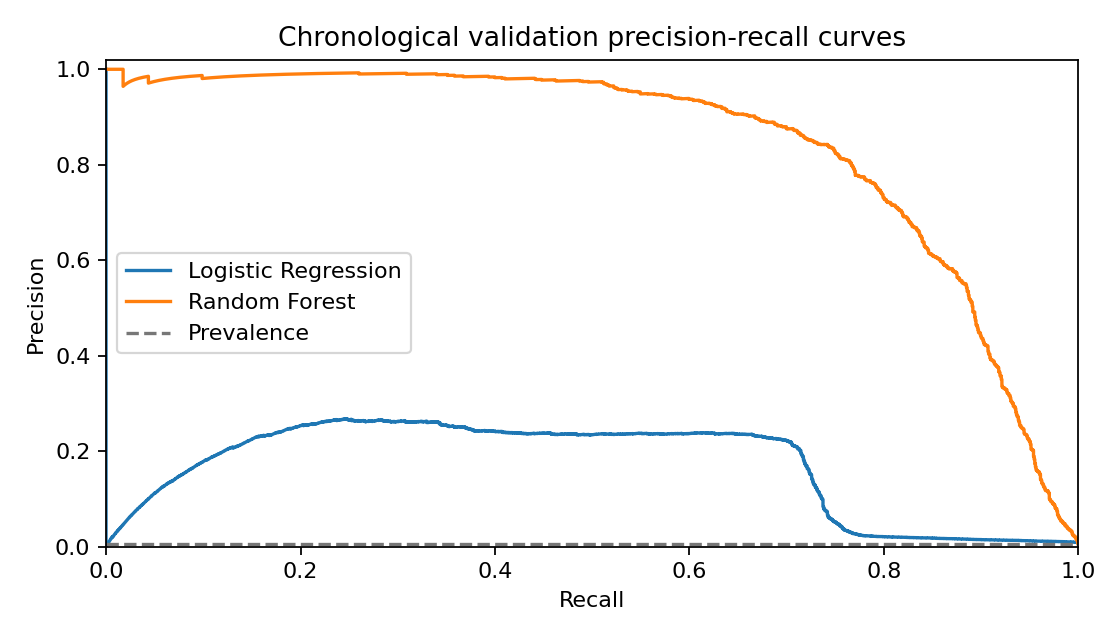

Training-fitted feature count: 78


In [4]:
display(comparison[['model','precision','recall','f1','average_precision','fp','fn','targets_met','fit_seconds']])
display(Image(filename=str(ARTIFACTS / 'validation_pr.png')))
print('Training-fitted feature count:', locked['feature_count'])

## 4 Reserved final test

Only the saved model and threshold are evaluated, once, on the official test. On rerun,
read the frozen result instead of rereading outcomes. Do not change the threshold after
seeing this result. A missed target is reported as a limitation, not corrected on test.
No classifier or transformation is fitted in this phase.

Reading saved final evaluation; test labels are not reopened.


,value
evaluated_utc,2026-10-19T13:26:51.834903+00:00
model,Random Forest
model_sha256,3dc619c459692de7c6e04fdf78d0f68b20b4eaa9633682...
test_sha256,12d553ab19440c752d2531ee1af44bb64f12cc3d3839f1...
scoring_seconds,3.635497
rows_per_second,152859.171976
threshold,0.576961
rows,555719
fraud,2145
accuracy,0.997733


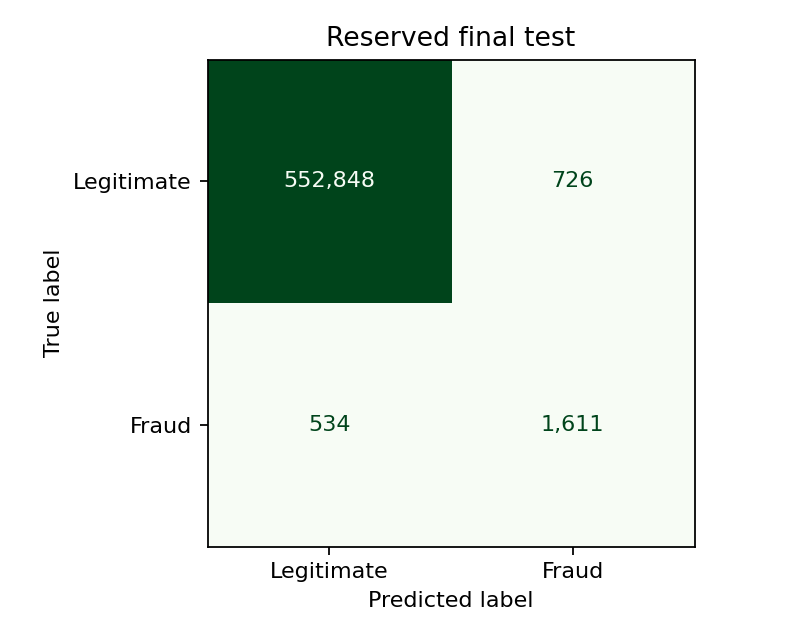

Preliminary targets met on final test: False


In [5]:
if (ARTIFACTS / 'final_test.json').exists():
    final = json.loads((ARTIFACTS / 'final_test.json').read_text())
    assert final['model_sha256'] == sha256(ARTIFACTS / 'selected_model.joblib')
    assert final['test_sha256'] == locked['data']['test_sha256']
    print('Reading saved final evaluation; test labels are not reopened.')
else:
    final = evaluate(ARTIFACTS, DATA_DIR)
display(pd.DataFrame([final]).T.rename(columns={0:'value'}))
display(Image(filename=str(ARTIFACTS / 'test_confusion.png')))
print('Preliminary targets met on final test:', final['targets_met'])

## 5 Coverage and subgroup checks

Report gender, category and seen/unseen-customer groups descriptively. Groups with
fewer than 30 fraud cases receive a support warning. Differences are not evidence of
causation or fairness certification. The retained age, gender and geographic variables
can serve as proxies; future ablations must use development data, not tune on test.

In [6]:
subgroups = pd.read_csv(ARTIFACTS / 'test_subgroups.csv').fillna('')
display(subgroups)
print('Original test cards unseen in the training period:', locked['data']['test_cards_unseen_in_training'])

,field,group,rows,fraud,tp,fp,fn,tn,recall,precision,false_positive_rate,support_warning
0,gender,F,304886,1164,767,498,397,303224,0.658935,0.606324,0.00164,
1,gender,M,250833,981,844,228,137,249624,0.860347,0.787313,0.000913,
2,category,entertainment,40104,59,49,17,10,40028,0.830508,0.742424,0.000425,
3,category,food_dining,39268,54,0,0,54,39214,0.000000,,0.0,
4,category,gas_transport,56370,154,96,2,58,56214,0.623377,0.979592,0.000036,
5,category,grocery_net,19426,41,0,1,41,19384,0.000000,0.0,0.000052,
6,category,grocery_pos,52553,485,479,19,6,52049,0.987629,0.961847,0.000365,
7,category,health_fitness,36674,52,0,0,52,36622,0.000000,,0.0,
8,category,home,52345,67,27,35,40,52243,0.402985,0.435484,0.000669,
9,category,kids_pets,48692,65,5,25,60,48602,0.076923,0.166667,0.000514,


Original test cards unseen in the training period: 16


## 6 Saved inference pipeline and demo sample

This is an unlabeled sample from validation, not a new performance estimate. It excludes
names, addresses, card numbers and DOB from displayed/downloaded outputs. Extra input
labels are ignored. Model scores are uncalibrated and are not fraud probabilities.
The local dashboard uses this exact pipeline and does not retrain on upload.

In [7]:
bundle = load_bundle(ARTIFACTS / 'selected_model.joblib')
sample = pd.read_csv(ARTIFACTS / 'demo_transactions.csv')
scored = score_transactions(sample, bundle)
display(scored.head(15))
print('Rows:', len(scored), '| Review flags:', int(scored.review_flag.sum()))
assert 'is_fraud' not in scored and 'cc_num' not in scored and 'dob' not in scored

,row_number,transaction_time,category,amount_usd,model_score,review_flag
592,593,2020-05-25 22:53:56,shopping_pos,887.65,0.966565,True
92,93,2020-06-03 22:13:35,shopping_net,1088.48,0.950275,True
378,379,2020-04-30 23:54:55,shopping_pos,891.32,0.949213,True
616,617,2020-06-18 23:40:39,misc_net,753.08,0.946261,True
655,656,2020-05-12 01:57:33,grocery_pos,330.20,0.916841,True
937,938,2020-05-07 01:00:24,grocery_pos,294.33,0.904612,True
302,303,2020-06-18 23:33:13,misc_net,802.56,0.813694,True
862,863,2020-05-01 00:30:46,gas_transport,19.08,0.698661,True
145,146,2020-06-09 15:57:36,shopping_pos,1123.97,0.676200,True
756,757,2020-06-01 15:39:12,shopping_pos,831.99,0.533443,False


Rows: 1000 | Review flags: 9


## 7 Interpretation and remaining work

Use the measured tables above: precision measures how many flags were fraud, recall
measures how much labeled fraud was detected, and false alerts/missed fraud quantify
the review trade-off. Accuracy alone is misleading under severe imbalance.

The saved local run selected Random Forest. Its final-test recall was below the
preliminary 80% target, even though the validation target was met. Synthetic historical
U.S. patterns and repeated customers limit generalization. These are classroom results,
not proven production banking performance. Batch scoring throughput is local/model-only
timing, not a guaranteed end-to-end latency. No real-time banking actions are supported.

Next: teammate usability checks, instructor final rubric, final report and slides.
The local application is launched from the project folder with:
`python -m uvicorn app:app --host 127.0.0.1 --port 8765`.
The source-only Colab fallback contains modeling functions, not the browser application;
use the project ZIP for the full local demo.

Method reference: [scikit-learn threshold tuning](https://scikit-learn.org/1.5/modules/classification_threshold.html).
Thresholds are selected on separate validation records, never on the official test.